In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("bank-additional-full.csv", sep=";")

In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.shape

(41188, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [6]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [7]:
df["y"].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [8]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [9]:
df["y"].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [10]:
df["y"].value_counts(normalize=True) * 100

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64

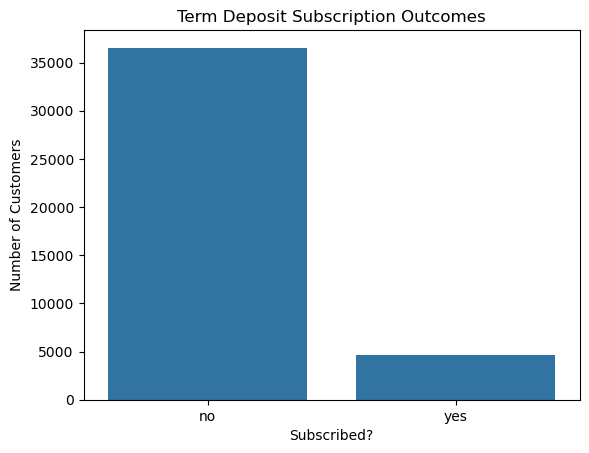

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="y")
plt.title("Term Deposit Subscription Outcomes")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Customers")
plt.show()

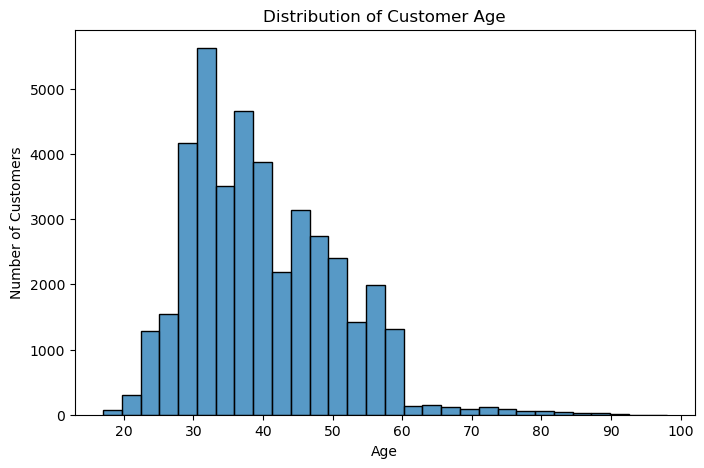

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=30)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

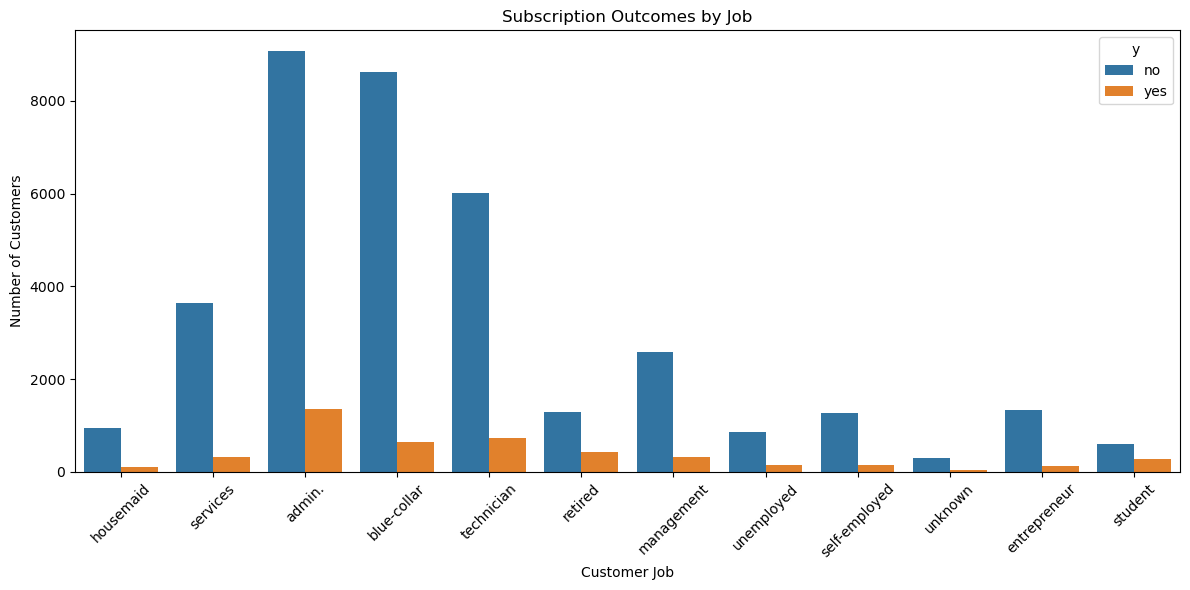

In [13]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="job",
    hue="y"
)

plt.title("Subscription Outcomes by Job")
plt.xlabel("Customer Job")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
job_rates = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_rates = job_rates.sort_values(
    by="yes",
    ascending=False
)

job_rates

y,no,yes
job,,
student,68.571429,31.428571
retired,74.767442,25.232558
unemployed,85.798817,14.201183
admin.,87.027442,12.972558
management,88.782490,11.217510
unknown,88.787879,11.212121
technician,89.173958,10.826042
self-employed,89.514426,10.485574
housemaid,90.000000,10.000000


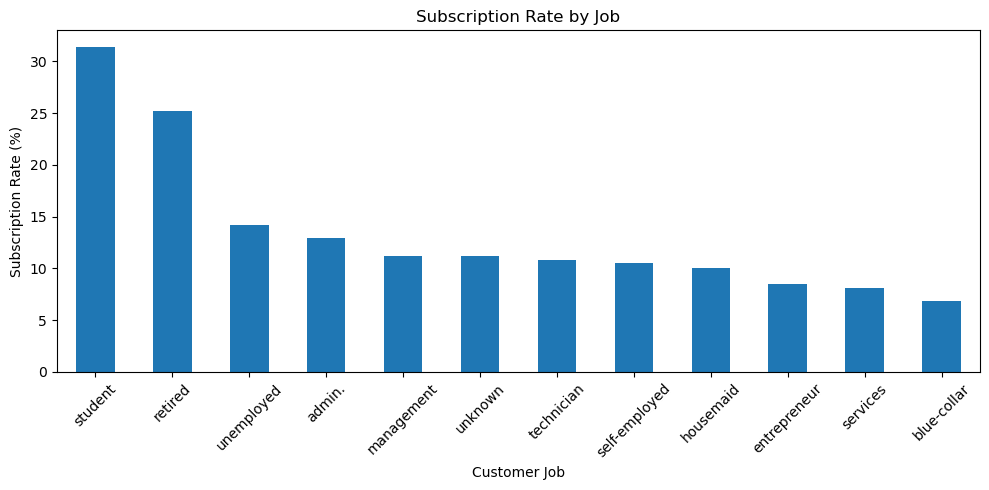

In [15]:
job_rates["yes"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Subscription Rate by Job")
plt.xlabel("Customer Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

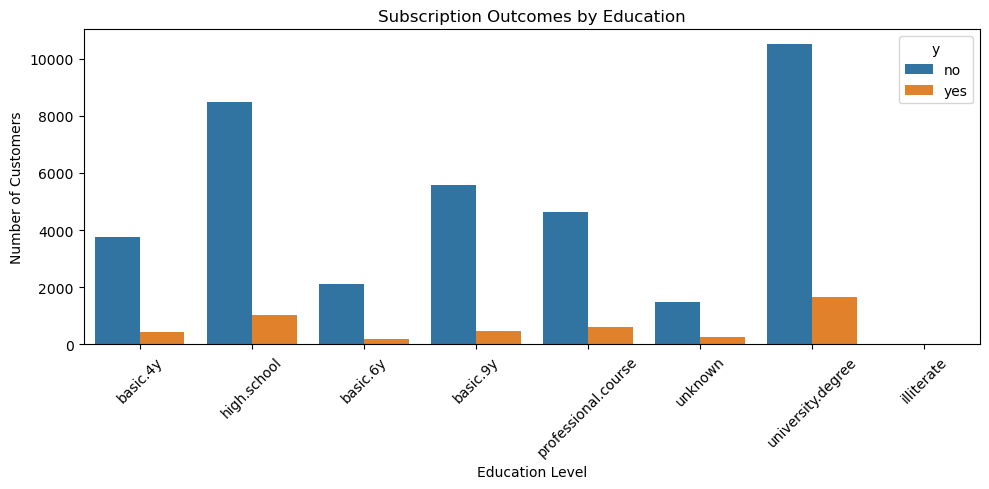

In [16]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="education", hue="y")

plt.title("Subscription Outcomes by Education")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
education_rates = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_rates.sort_values(
    by="yes",
    ascending=False
)

y,no,yes
education,,
illiterate,77.777778,22.222222
unknown,85.499711,14.500289
university.degree,86.275477,13.724523
professional.course,88.651535,11.348465
high.school,89.164477,10.835523
basic.4y,89.750958,10.249042
basic.6y,91.797557,8.202443
basic.9y,92.175352,7.824648


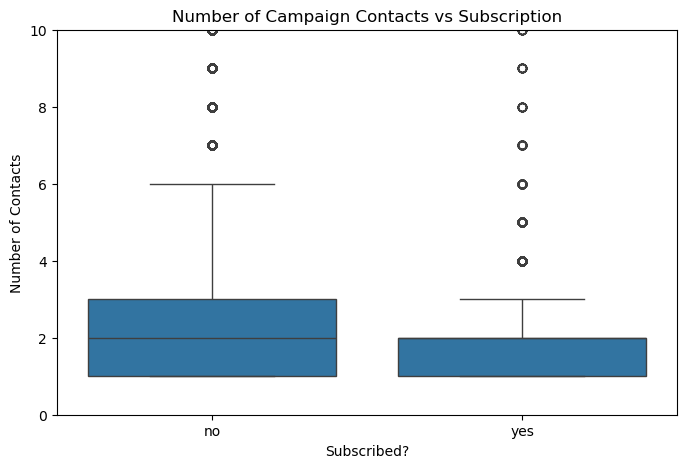

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="y", y="campaign")

plt.title("Number of Campaign Contacts vs Subscription")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Contacts")
plt.ylim(0, 10)
plt.show()

### Exploratory Data Analysis — Initial Findings

1. The dataset contains customer and marketing campaign information.
2. Subscription outcomes are divided into yes and no.
3. Customer characteristics and campaign variables may be associated
   with subscription outcomes.
4. Further analysis is needed before drawing conclusions.

In [20]:
(df == "unknown").sum().sort_values(ascending=False)

default           8597
education         1731
housing            990
loan               990
job                330
marital             80
age                  0
poutcome             0
nr.employed          0
euribor3m            0
cons.conf.idx        0
cons.price.idx       0
emp.var.rate         0
duration             0
previous             0
pdays                0
campaign             0
day_of_week          0
month                0
contact              0
y                    0
dtype: int64

In [21]:
df[["duration", "y"]].head(10)

,duration,y
0,261,no
1,149,no
2,226,no
3,151,no
4,307,no
5,198,no
6,139,no
7,217,no
8,380,no
9,50,no


In [22]:
(df == "unknown").sum().sort_values(ascending=False)

default           8597
education         1731
housing            990
loan               990
job                330
marital             80
age                  0
poutcome             0
nr.employed          0
euribor3m            0
cons.conf.idx        0
cons.price.idx       0
emp.var.rate         0
duration             0
previous             0
pdays                0
campaign             0
day_of_week          0
month                0
contact              0
y                    0
dtype: int64

In [23]:
df[["duration", "y"]].head(10)

,duration,y
0,261,no
1,149,no
2,226,no
3,151,no
4,307,no
5,198,no
6,139,no
7,217,no
8,380,no
9,50,no


In [24]:
y = df["y"]

In [25]:
X = df.drop(columns=["y", "duration"])

In [26]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (41188, 19)
Target shape: (41188,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (32950, 19)
Testing features: (8238, 19)
Training target: (32950,)
Testing target: (8238,)


###preparing the data for logistic regression

In [29]:
categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numerical columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_cols),
    ("numerical", numerical_pipeline, numerical_cols)
])

In [31]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [32]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [33]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8350327749453751

Classification Report:

              precision    recall  f1-score   support

          no       0.95      0.86      0.90      7310
         yes       0.37      0.65      0.47       928

    accuracy                           0.84      8238
   macro avg       0.66      0.75      0.69      8238
weighted avg       0.88      0.84      0.85      8238

ROC-AUC: 0.8009417454832776

Confusion Matrix:

[[6279 1031]
 [ 328  600]]


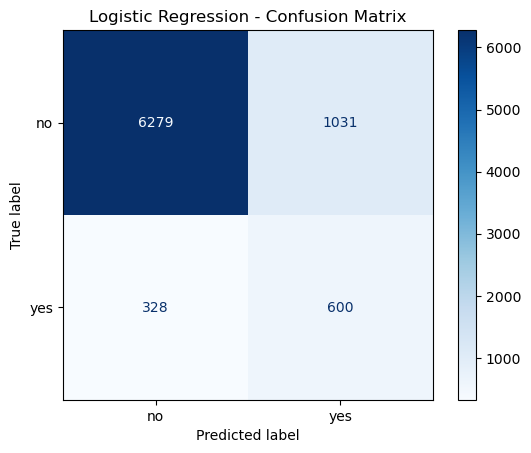

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["no", "yes"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [36]:
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_proba))
print(classification_report(y_test, rf_pred))

Random Forest Results
Accuracy: 0.8897790725904345
ROC-AUC: 0.7985153338600879
              precision    recall  f1-score   support

          no       0.94      0.94      0.94      7310
         yes       0.51      0.52      0.51       928

    accuracy                           0.89      8238
   macro avg       0.72      0.73      0.73      8238
weighted avg       0.89      0.89      0.89      8238



In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="yes"),
        "Recall": recall_score(y_test, y_pred, pos_label="yes"),
        "F1-score": f1_score(y_test, y_pred, pos_label="yes"),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, pos_label="yes"),
        "Recall": recall_score(y_test, rf_pred, pos_label="yes"),
        "F1-score": f1_score(y_test, rf_pred, pos_label="yes"),
        "ROC-AUC": roc_auc_score(y_test, rf_proba)
    }
])

results.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.835,0.368,0.647,0.469,0.801
1,Random Forest,0.890,0.511,0.519,0.515,0.799


In [39]:
%pip show xgboost

Name: xgboost
Version: 3.4.1
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: C:\Users\MIRUTHULA\anaconda3\Lib\site-packages
Requires: numpy, scipy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [40]:
import sys
print(sys.version)
print(sys.executable)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
C:\Users\MIRUTHULA\anaconda3\python.exe


In [41]:
%pip install --upgrade xgboost

Note: you may need to restart the kernel to use updated packages.


In [42]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [43]:
%pip show xgboost numpy scikit-learn

Name: xgboost
Version: 3.4.1
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: C:\Users\MIRUTHULA\anaconda3\Lib\site-packages
Requires: numpy, scipy
Required-by: 
---
Name: numpy
Version: 2.3.5
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License: Copyright (c) 2005-2025, NumPy Developers.
 All rights reserved.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions are
 met:

     * Redistributions of source code must retain the above copyright
        notice, this list of conditions and the following disclaimer.

     * Redistributions in binary form must reproduce the above
        copyright notice, this list of conditions and the following
        disclaimer in the documentation a

In [44]:
import sys
print(sys.version)
print(sys.executable)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
C:\Users\MIRUTHULA\anaconda3\python.exe


In [45]:
print("Logistic Regression:", type(model).__name__)
print("Random Forest:", type(rf_model).__name__)

Logistic Regression: Pipeline
Random Forest: Pipeline


In [46]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="yes"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="yes"
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label="yes"
        ),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(
            y_test, rf_pred, pos_label="yes"
        ),
        "Recall": recall_score(
            y_test, rf_pred, pos_label="yes"
        ),
        "F1-score": f1_score(
            y_test, rf_pred, pos_label="yes"
        ),
        "ROC-AUC": roc_auc_score(y_test, rf_proba)
    }
])

results.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.835,0.368,0.647,0.469,0.801
1,Random Forest,0.890,0.511,0.519,0.515,0.799


###now finding most influential model from random forest model

In [47]:
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
60,numerical__euribor3m,0.137788
53,numerical__age,0.110970
61,numerical__nr.employed,0.081490
57,numerical__emp.var.rate,0.065102
54,numerical__campaign,0.062327
59,numerical__cons.conf.idx,0.037474
58,numerical__cons.price.idx,0.026682
55,numerical__pdays,0.023488
27,categorical__housing_no,0.016076
29,categorical__housing_yes,0.016028


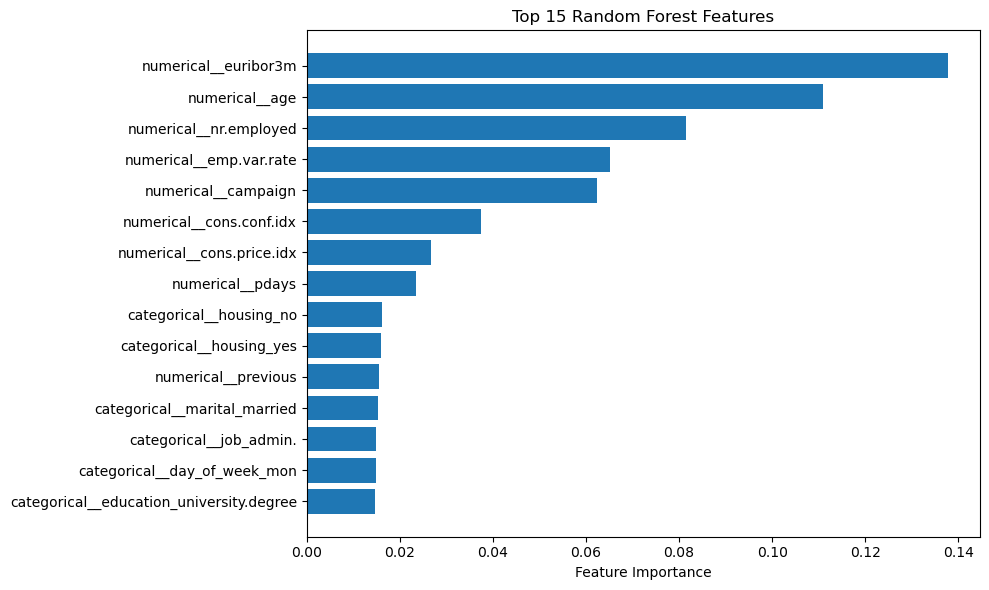

In [48]:
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [49]:
importance_df.head(10)

,Feature,Importance
60,numerical__euribor3m,0.137788
53,numerical__age,0.110970
61,numerical__nr.employed,0.081490
57,numerical__emp.var.rate,0.065102
54,numerical__campaign,0.062327
59,numerical__cons.conf.idx,0.037474
58,numerical__cons.price.idx,0.026682
55,numerical__pdays,0.023488
27,categorical__housing_no,0.016076
29,categorical__housing_yes,0.016028


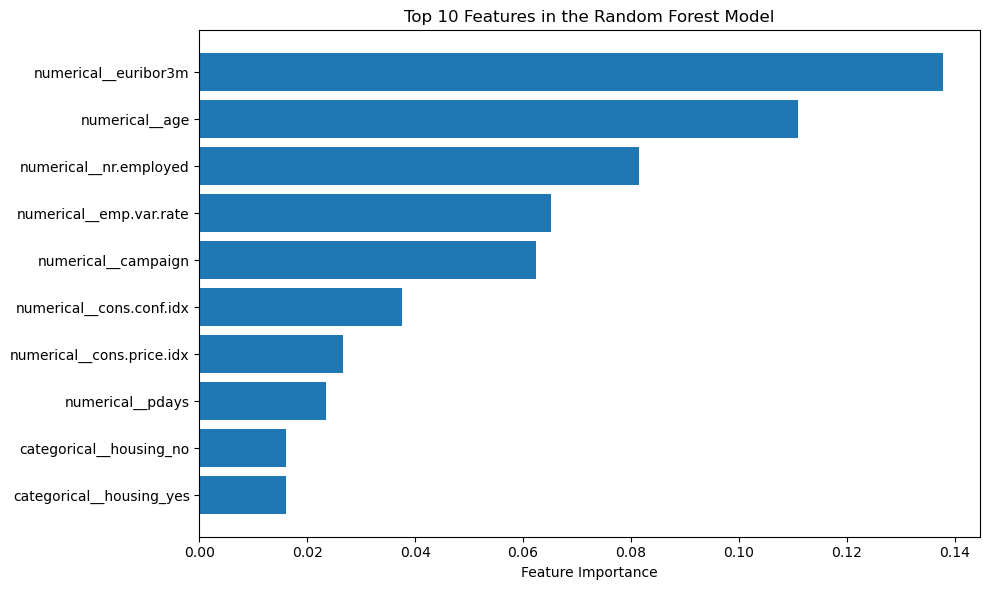

In [50]:
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Features in the Random Forest Model")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [51]:
import joblib

joblib.dump(rf_model, "bank_marketing_model.pkl")

['bank_marketing_model.pkl']

In [52]:
results.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.835,0.368,0.647,0.469,0.801
1,Random Forest,0.890,0.511,0.519,0.515,0.799


In [54]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="yes"),
        "Recall": recall_score(y_test, y_pred, pos_label="yes"),
        "F1-score": f1_score(y_test, y_pred, pos_label="yes"),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, pos_label="yes"),
        "Recall": recall_score(y_test, rf_pred, pos_label="yes"),
        "F1-score": f1_score(y_test, rf_pred, pos_label="yes"),
        "ROC-AUC": roc_auc_score(y_test, rf_proba)
    }
])

results.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.835,0.368,0.647,0.469,0.801
1,Random Forest,0.890,0.511,0.519,0.515,0.799


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

prep = rf_model.named_steps["preprocessor"]

extra = {
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42),
}

extra_proba = {}
rows = []
for name, clf in extra.items():
    m = Pipeline([("preprocessor", clone(prep)), ("model", clf)])
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    extra_proba[name] = proba
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, pos_label="yes"),
                 "Recall": recall_score(y_test, pred, pos_label="yes"),
                 "F1-score": f1_score(y_test, pred, pos_label="yes"),
                 "ROC-AUC": roc_auc_score(y_test, proba)})

results_all = pd.concat([results, pd.DataFrame(rows)], ignore_index=True)
results_all.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.835,0.368,0.647,0.469,0.801
1,Random Forest,0.890,0.511,0.519,0.515,0.799
2,Decision Tree,0.821,0.347,0.667,0.456,0.790
3,Gradient Boosting,0.901,0.677,0.233,0.346,0.809


In [57]:
y_true = (y_test == "yes").astype(int)
all_proba = {"Logistic Regression": y_proba, "Random Forest": rf_proba, **extra_proba}

rows = []
for name, proba in all_proba.items():
    for t in [0.2, 0.3, 0.4, 0.5]:
        p = (proba >= t).astype(int)
        rows.append({"Model": name, "Threshold": t,
                     "Precision": precision_score(y_true, p, zero_division=0),
                     "Recall": recall_score(y_true, p),
                     "F1": f1_score(y_true, p)})
pd.DataFrame(rows).round(3)

,Model,Threshold,Precision,Recall,F1
0,Logistic Regression,0.2,0.122,0.971,0.217
1,Logistic Regression,0.3,0.166,0.866,0.278
2,Logistic Regression,0.4,0.272,0.734,0.397
3,Logistic Regression,0.5,0.368,0.647,0.469
4,Random Forest,0.2,0.256,0.724,0.378
5,Random Forest,0.3,0.367,0.653,0.470
6,Random Forest,0.4,0.444,0.596,0.509
7,Random Forest,0.5,0.511,0.519,0.515
8,Decision Tree,0.2,0.124,0.952,0.220
9,Decision Tree,0.3,0.147,0.892,0.252


In [58]:
print("duration" in X_train.columns)

False


In [59]:
results_all.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.835,0.368,0.647,0.469,0.801
1,Random Forest,0.890,0.511,0.519,0.515,0.799
2,Decision Tree,0.821,0.347,0.667,0.456,0.790
3,Gradient Boosting,0.901,0.677,0.233,0.346,0.809


In [60]:
from sklearn.model_selection import cross_val_score
gb = Pipeline([("preprocessor", clone(prep)),
               ("model", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42))])
scores = cross_val_score(gb, X_train, y_train, cv=5, scoring="roc_auc", n_jobs=-1)
print(scores.round(3), "mean:", scores.mean().round(3), "std:", scores.std().round(3))

[0.816 0.78  0.795 0.786 0.801] mean: 0.796 std: 0.013


In [61]:
tmp = X_train.copy()
tmp["subscribed"] = (y_train == "yes").astype(int)
for col in ["contact", "poutcome", "month", "job"]:
    print(tmp.groupby(col)["subscribed"].agg(["mean", "count"]).round(3).sort_values("mean", ascending=False), "\n")

            mean  count
contact                
cellular   0.147  20908
telephone  0.053  12042 

              mean  count
poutcome                 
success      0.649   1105
failure      0.144   3429
nonexistent  0.088  28416 

        mean  count
month              
dec    0.503    143
mar    0.498    436
sep    0.446    464
oct    0.433    587
apr    0.205   2085
aug    0.107   4948
jun    0.104   4247
nov    0.102   3266
jul    0.092   5763
may    0.063  11011 

                mean  count
job                        
student        0.305    711
retired        0.255   1366
unemployed     0.145    798
admin.         0.129   8314
unknown        0.125    265
management     0.115   2345
self-employed  0.108   1099
technician     0.108   5400
housemaid      0.101    855
entrepreneur   0.086   1160
services       0.079   3196
blue-collar    0.069   7441 



## Recommendations for the Marketing Team

1. Use cellular contact instead of telephone. Cellular calls converted at 14.7% (20,908 calls)
   against 5.3% for telephone (12,042 calls), about 2.8 times higher. Part of this gap may reflect
   when each channel was used, so I recommend testing before moving the whole budget.

2. Prioritise customers with a previous successful campaign. 64.9% of customers whose previous
   outcome was "success" subscribed, against 8.8% for those with no previous campaign. The group is
   small (1,105 customers), so it is a high-value follow-up list rather than a volume source.

3. Target students and retired customers. Students subscribed at 30.5% (711 customers) and
   retired customers at 25.5% (1,366), against 11.3% overall. Blue-collar workers had the lowest
   rate (6.9%) but are the largest group after admin (7,441 calls), so they use up a lot of call
   time for few subscriptions.

4. Rethink the timing of campaign effort. May had the most calls (11,011, about a third of all
   calls) and the lowest rate (6.3%). December, March, September and October converted at 43% to
   50%, but each had under 600 calls, so those rates may reflect which customers were called
   rather than the month itself. A sensible step is to test a shift of some calls into these
   months and measure the result.

5. Rank customers with the model. Gradient Boosting at a threshold of about 0.2 found 59% of
   subscribers with 48% of calls successful, about 4 times the 11.3% random baseline. Calling the
   highest-scoring customers first improves results for the same call budget.

6. Avoid repeated calls to the same customer. In the model, a higher number of contacts in the
   current campaign slightly lowered the chance of subscribing.

Caveat: These are associations in historical data, not proven causes, and the economic
indicators (euribor 3m, employment variation) were also among the strongest predictors, so
results depend partly on market conditions at the time of the call.